# Electrodynamics from Scratch — Lecture 10: The Wave Equation and D'Alembert's Solution

Maxwell's equations in vacuum reduce, for each component of $\mathbf{E}$ and $\mathbf{B}$, to the wave equation
$$
\frac{\partial^2 u}{\partial t^2} = c^2 \, \frac{\partial^2 u}{\partial x^2},
$$
with the wave speed fixed by the electricity and magnetism of empty space, $c = 1/\sqrt{\varepsilon_0 \mu_0}$. This is the equation behind Lecture 1's displacement current: changing $\mathbf{E}$ makes $\mathbf{B}$, changing $\mathbf{B}$ makes $\mathbf{E}$, and the pair propagates. It is a *hyperbolic* equation — information travels at finite speed — in contrast to the *elliptic* Laplace and Poisson equations of electrostatics, where the solution everywhere adjusts instantaneously to the charges.

For the 1D wave equation with initial displacement $f(x) = u(x,0)$ and initial velocity $g(x) = \partial_t u(x,0)$, d'Alembert wrote down the exact solution:
$$
u(x,t) \;=\; \frac{1}{2}\bigl[f(x - ct) + f(x + ct)\bigr] \;+\; \frac{1}{2c} \int_{x-ct}^{x+ct} g(s)\, ds .
$$
Everything travels: the first term is two half-amplitude copies of the initial shape, one sliding right at speed $c$ and one sliding left at speed $c$, and the integral term converts the initial velocity into displacement. No boundary conditions, no series — the solution at $(x,t)$ depends only on the initial data inside the interval $[x-ct,\, x+ct]$, the *domain of dependence*, which is causality made arithmetic.

In this notebook we build the d'Alembert solution with the course package (`eds.dalembert`), watch a plucked string split into left- and right-moving halves, send a single pulse in one direction, collide two pulses, and then revisit the field of a spherical shell from electrostatics to contrast the elliptic world of Laplace with the propagating world of waves.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

## A plucked string splits in two

We pluck a string into a triangular bump centered at $x = 0$ and release it from rest ($g = 0$). With zero initial velocity the integral term in d'Alembert's formula vanishes, so the solution is exactly two half-height copies of the triangle sliding apart at speed $c$. We use `eds.dalembert` to evaluate $u(x,t)$ at several times and plot the curves on one axes.

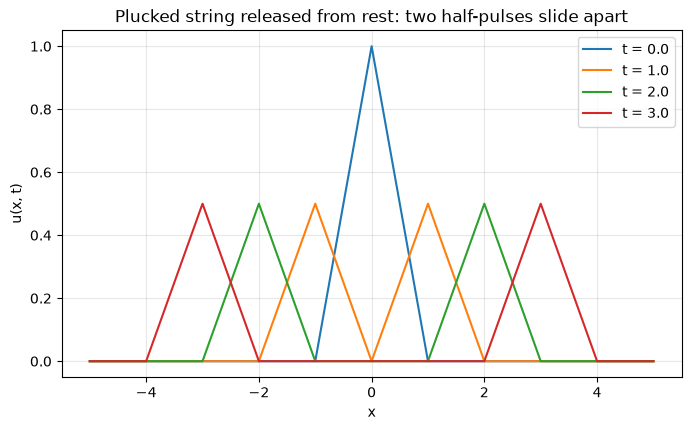

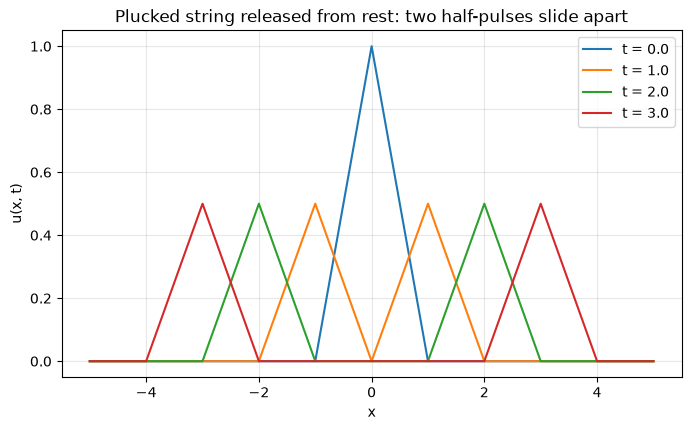

In [2]:
x = np.linspace(-5.0, 5.0, 201)
c = 1.0

def triangle(xp, half_width=1.0, height=1.0):
    """Plucked-string shape: a triangular bump of given half-width."""
    return height * np.clip(1.0 - np.abs(xp) / half_width, 0.0, None)

times = [0.0, 1.0, 2.0, 3.0]
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in times:
    u = eds.dalembert(triangle, lambda s: 0.0 * s, x, t, c=c)
    ax.plot(x, u, label=f"t = {t:.1f}")
ax.set_xlabel("x")
ax.set_ylabel("u(x, t)")
ax.set_title("Plucked string released from rest: two half-pulses slide apart")
ax.legend()
ax.grid(alpha=0.3)
fig

## A smooth pulse: the Gaussian bump

The same physics with a smooth initial shape $f(x) = e^{-(x - x_0)^2 / 2\sigma^2}$, again released from rest. The d'Alembert formula reproduces the familiar picture: the bump flattens to half height at $t=0$ and then two Gaussian halves of the original amplitude depart in opposite directions, each traveling rigidly at speed $c$ without changing shape — the signature of a nondispersive wave equation.

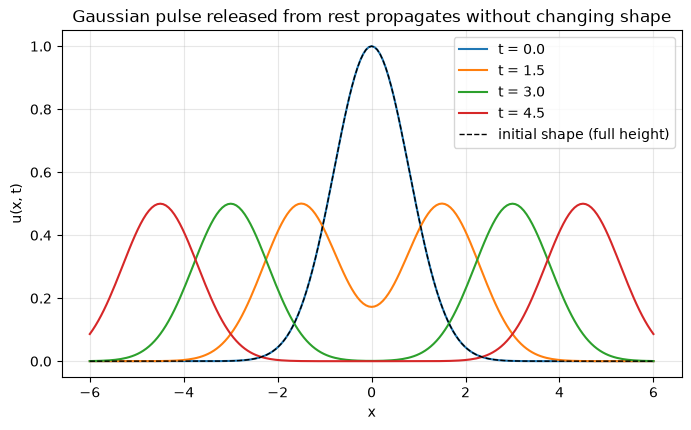

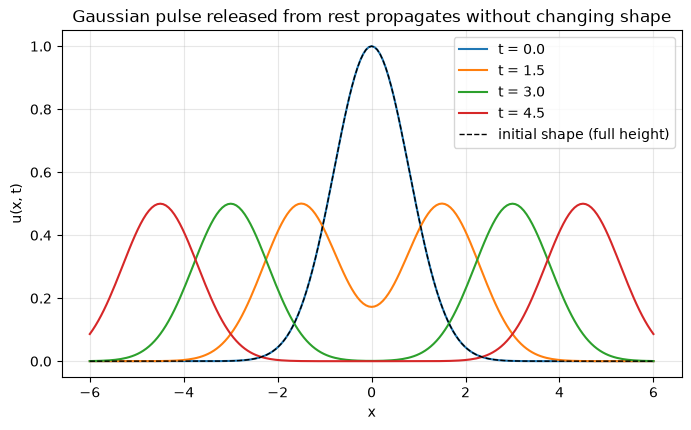

In [3]:
x = np.linspace(-6.0, 6.0, 201)
c = 1.0
x0, sigma = 0.0, 0.8

def gaussian_bump(xp):
    return np.exp(-((xp - x0) ** 2) / (2.0 * sigma**2))

times = [0.0, 1.5, 3.0, 4.5]
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in times:
    u = eds.dalembert(gaussian_bump, lambda s: 0.0 * s, x, t, c=c)
    ax.plot(x, u, label=f"t = {t:.1f}")
ax.plot(x, gaussian_bump(x), "k--", lw=1, label="initial shape (full height)")
ax.set_xlabel("x")
ax.set_ylabel("u(x, t)")
ax.set_title("Gaussian pulse released from rest propagates without changing shape")
ax.legend()
ax.grid(alpha=0.3)
fig

## A wave traveling in one direction

The two halves move apart because the string is released from rest. If instead we launch the string with initial velocity $g(x) = -c\, f'(x)$, the integral term contributes $(f(x-ct) - f(x+ct))/2$, and d'Alembert collapses to a *single* right-moving wave $u(x,t) = f(x - ct)$: the left-moving copy is exactly cancelled. We build $f'$ analytically for the Gaussian and check that `eds.dalembert` reproduces the shifted pulse $f(x - ct)$ at every time.

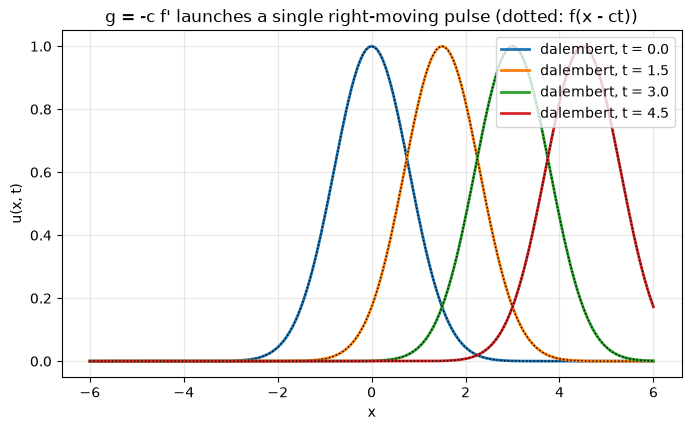

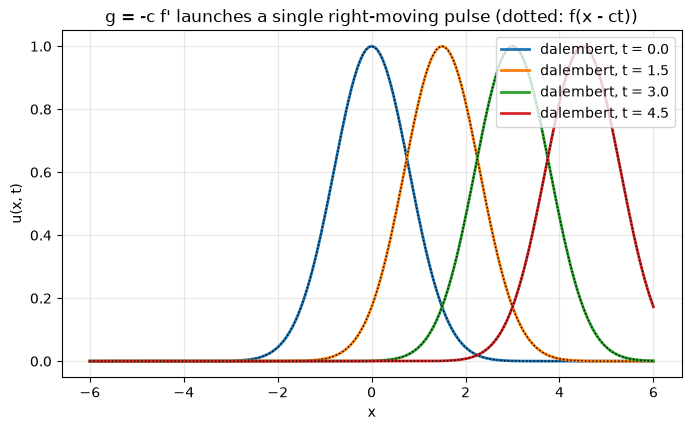

In [4]:
x = np.linspace(-6.0, 6.0, 201)
c = 1.0
x0, sigma = 0.0, 0.8

def gaussian_bump(xp):
    return np.exp(-((xp - x0) ** 2) / (2.0 * sigma**2))

def gaussian_slope(xp):
    """df/dx for the Gaussian bump."""
    return -(xp - x0) / sigma**2 * gaussian_bump(xp)

times = [0.0, 1.5, 3.0, 4.5]
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in times:
    u = eds.dalembert(gaussian_bump, lambda s: -c * gaussian_slope(s), x, t, c=c)
    ax.plot(x, u, lw=2, label=f"dalembert, t = {t:.1f}")
    ax.plot(x, gaussian_bump(x - c * t), "k:", lw=1)
ax.set_xlabel("x")
ax.set_ylabel("u(x, t)")
ax.set_title("g = -c f' launches a single right-moving pulse (dotted: f(x - ct))")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig

## Superposition: two pulses passing through each other

The wave equation is *linear*, so if $u_1$ and $u_2$ are solutions then $u_1 + u_2$ is too. We launch a narrow right-moving pulse (initial velocity $-c f'$) and a taller, wider left-moving pulse (initial velocity $+c h'$) toward each other, superpose the two d'Alembert solutions, and watch them pass through one another and emerge unchanged — no scattering, no distortion, just momentary overlap.

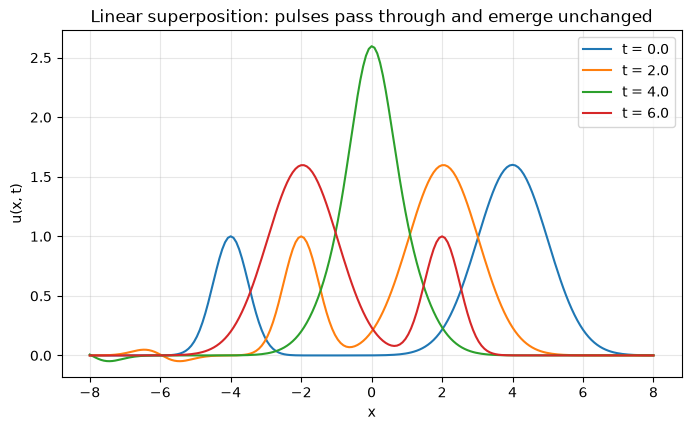

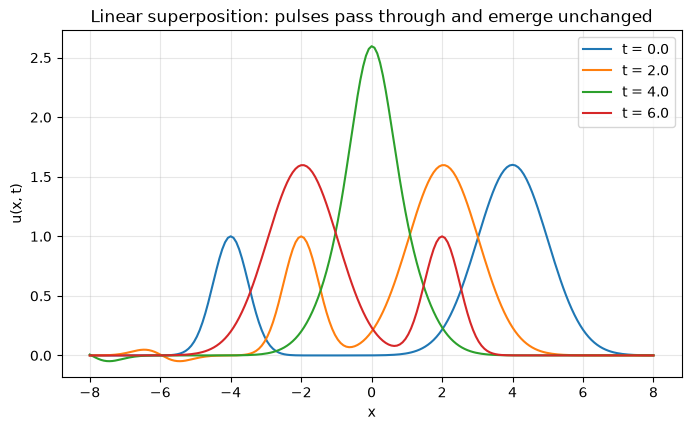

In [5]:
x = np.linspace(-8.0, 8.0, 201)
c = 1.0

def pulse_right(xp):   # starts at x = -4, will move right
    return 1.0 * np.exp(-((xp + 4.0) ** 2) / (2.0 * 0.5**2))

def pulse_right_slope(xp):
    return -(xp + 4.0) / 0.5**2 * pulse_right(xp)

def pulse_left(xp):    # starts at x = +4, will move left
    return 1.6 * np.exp(-((xp - 4.0) ** 2) / (2.0 * 1.0**2))

def pulse_left_slope(xp):
    return -(xp - 4.0) / 1.0**2 * pulse_left(xp)

def total_wave(xx, t):
    """Superposition of a right-mover and a left-mover (linear wave equation)."""
    u_right = eds.dalembert(pulse_right, lambda s: -c * pulse_right_slope(s), xx, t, c=c)
    u_left = eds.dalembert(pulse_left, lambda s: +c * pulse_left_slope(s), xx, t, c=c)
    return u_right + u_left

times = [0.0, 2.0, 4.0, 6.0]
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in times:
    ax.plot(x, total_wave(x, t), label=f"t = {t:.1f}")
ax.set_xlabel("x")
ax.set_ylabel("u(x, t)")
ax.set_title("Linear superposition: pulses pass through and emerge unchanged")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig

## The electrostatics side of the lecture: the spherical shell revisited

Waves obey a hyperbolic equation; the static fields of Lecture 1 obey the elliptic $\nabla^2 V = -\rho/\varepsilon_0$, where nothing propagates and the field everywhere is fixed at once by the charge distribution. As a reminder of that world we revisit the charged spherical shell of radius $R$ with `eds.shell_field`: the exact result is $\mathbf{E} = 0$ inside and $\mathbf{E} = q\,\hat{\mathbf{r}}/(4\pi\varepsilon_0 r^2)$ outside — the shell's field is indistinguishable from a point charge's beyond $R$. We verify both statements numerically against the point-charge field and the analytic $1/r^2$ law.

max |E_shell| inside  r < R : 0.000e+00 V/m
max |E_shell - E_point| for r > R : 9.537e-07 V/m
max |E_shell - analytic| for r > R: 9.537e-07 V/m


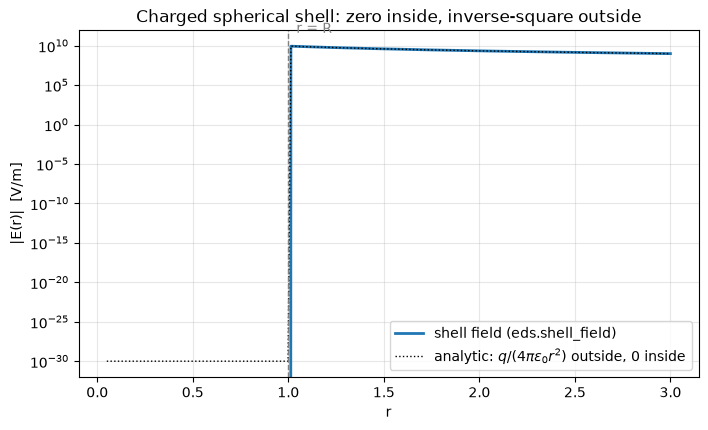

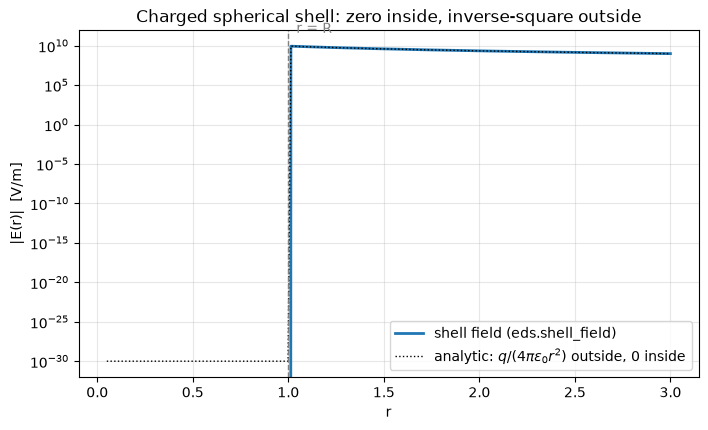

In [6]:
q, R = 1.0, 1.0
r = np.linspace(0.05, 3.0, 200)
points = np.zeros((r.size, 3))
points[:, 0] = r  # field points along the +x axis

E_shell = eds.shell_field(q, R, points)
E_point = eds.point_charge_field(q, np.zeros(3), points)
E_analytic = np.zeros_like(E_shell)
outside = r > R
E_analytic[outside, 0] = q / (4.0 * np.pi * eds.EPSILON_0 * r[outside] ** 2)

print(f"max |E_shell| inside  r < R : {np.max(np.linalg.norm(E_shell[~outside], axis=1)):.3e} V/m")
print(f"max |E_shell - E_point| for r > R : {np.max(np.linalg.norm(E_shell[outside] - E_point[outside], axis=1)):.3e} V/m")
print(f"max |E_shell - analytic| for r > R: {np.max(np.linalg.norm(E_shell[outside] - E_analytic[outside], axis=1)):.3e} V/m")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(r, np.linalg.norm(E_shell, axis=1), lw=2, label="shell field (eds.shell_field)")
ax.semilogy(r, np.linalg.norm(E_analytic, axis=1) + 1e-30, "k:", lw=1,
            label=r"analytic: $q/(4\pi\varepsilon_0 r^2)$ outside, 0 inside")
ax.axvline(R, color="gray", ls="--", lw=1)
ax.text(R, ax.get_ylim()[1] * 0.5, "  r = R", color="gray")
ax.set_xlabel("r")
ax.set_ylabel(r"|E(r)|  [V/m]")
ax.set_title("Charged spherical shell: zero inside, inverse-square outside")
ax.legend()
ax.grid(alpha=0.3, which="both")
fig

## Exercises

1. **Domain of dependence.** Explain, using d'Alembert's formula, why changing the initial displacement $f$ at a single point $x_1$ cannot affect the solution at $(x, t)$ unless $|x - x_1| \leq ct$. What is the analogue of this statement for light emitted by a charge (hint: the retarded time $\tau = t - |\mathbf{r} - \mathbf{r}'|/c$ from `eds.retarded_time`)?

2. **Zero initial velocity.** For the plucked triangle in the first worked cell, predict analytically the height and positions of the two peaks at $t = 2.5$, then verify your prediction by evaluating `eds.dalembert(triangle, lambda s: 0.0 * s, x, 2.5, c=1.0)` on a grid.

3. **One-direction waves.** In the third worked cell we used $g = -c f'$ to launch a right-moving pulse. Show algebraically that $g = +c f'$ gives $u(x,t) = f(x + ct)$, then modify the cell to launch a *left*-moving Gaussian and check that it exits at $x = -6$ for large $t$.

4. **Satisfying the wave equation.** Using `np.gradient` twice on the returned arrays (with grid spacing `dx`), verify numerically that the Gaussian-pulse solution satisfies $\partial_t^2 u = c^2 \partial_x^2 u$ at $t = 0$ and $t = 1$, by comparing $u(x, t + \Delta t)$ and $u(x, t - \Delta t)$ for a small $\Delta t$ (a finite-difference estimate of $\partial_t^2 u$).

5. **Collision vs. superposition.** In the collision cell, compute the maximum of $u$ at $t = 4.0$ (when the pulses overlap) and compare it with the sum of the two individual peak heights. Why is the wave equation's linearity the reason the maximum can briefly exceed either pulse alone, yet the pulses emerge unchanged?

6. **From shell to wave.** The shell field is static, but if the shell's charge were switched on suddenly at $t = 0$, electromagnetic news of it would travel outward at $c = 1/\sqrt{\varepsilon_0 \mu_0}$. Use `eds.C_LIGHT`, `eds.EPSILON_0` and `eds.MU_0` to compute that speed in m/s, and calculate how long the news takes to reach a detector at $r = 3$ m from a shell of radius $R = 1$ m. Then plot the final-state shell field along $x$ with `eds.shell_field` — the field the detector eventually measures.